## Multiplicação de Matrizes Paralela
### Programação Paralela e Distribuída (2026/2) - UFSCar

**Integrantes**
- Enzo Dezem Alves - 801743
- Gustavo Cesar Bento Laurindo - 821402
- Gustavo de Oliveira Gimenes - 820759
- Tiago de Paula Evangelista - 824369

### Introdução

Este trabalho aplica os conhecimentos teóricos e práticos da disciplina no estudo e no desenvolvimento de uma aplicação paralela relevante. O problema escolhido é a **multiplicação de matrizes**, retirado do conjunto da Maratona de Programação Paralela (SBAC-PAD). É uma operação central em computação científica, aprendizado de máquina e simulações numéricas, e seu alto custo computacional ($O(n^3)$) a torna um bom caso para explorar diferentes modelos de paralelismo.

Partindo de uma versão sequencial de referência, o problema é modelado e decomposto em tarefas independentes, e então implementado em três plataformas:

- **Memória compartilhada**, com threads usando OpenMP;
- **Memória distribuída**, com passagem de mensagens usando MPI;
- **GPU**, explorando o paralelismo massivo de dados com CUDA.

Mais do que apenas paralelizar, o objetivo é justificar as decisões de projeto de cada versão, analisando o impacto da comunicação, da granularidade das tarefas e do balanceamento de carga no desempenho obtido. Ao final, as implementações são comparadas em uma análise de desempenho (tempo de execução, speedup e eficiência).

### Utilitários

Infraestrutura compartilhada por todas as implementações: a medição de tempo padronizada, usada na análise de desempenho, e as funções que geram os diagramas.

#### Padronização da medição de tempo

Para que a análise de desempenho seja justa, **todas as implementações usam a mesma infraestrutura de medição**, definida uma única vez aqui:

- **`src/common.h`** (C/C++, incluído por todas as versões): leitura das dimensões, alocação, inicialização determinística, *checksum* e o relógio `wall_time()`, baseado em `clock_gettime(CLOCK_MONOTONIC)`. Todo programa é chamado como `./prog n m p`, ou `./prog n` para matrizes quadradas. Mede-se o **tempo de parede (*wall-clock*) apenas da multiplicação**: a alocação e a inicialização ficam fora da medição. Cada programa imprime uma linha no formato padronizado

  `RESULT,<implementação>,<n>,<m>,<p>,<workers>,<tempo_s>,<checksum>`

  em que `workers` é o número de threads, processos ou blocos usados (1 na versão sequencial).
- **Funções Python `compile_c` e `benchmark`** (célula abaixo): compilam os códigos e executam cada programa várias vezes, extraem a linha `RESULT` e guardam cada execução na tabela global `RESULTS`. A seção de Análise de desempenho usa essa tabela diretamente.

In [1]:
import os, re, subprocess, statistics
import numpy as np
import pandas as pd

os.makedirs("src/bin", exist_ok=True)
os.makedirs("assets", exist_ok=True)

RESULTS = []  # tabela global: uma linha por execução de qualquer implementação
_RESULT_RE = re.compile(
    r"^RESULT,([^,]+),(\d+),(\d+),(\d+),(\d+),([\d.eE+-]+),([\d.eE+-]+)$", re.M)

def parse_result(stdout):
    """Extrai a linha RESULT da saída de um programa."""
    m = _RESULT_RE.search(stdout)
    if m is None:
        return None
    impl, n, m_, p, workers, t, chk = m.groups()
    return dict(impl=impl, n=int(n), m=int(m_), p=int(p), workers=int(workers),
                time_s=float(t), checksum=float(chk))

def compile_c(src, out, compiler="gcc", flags="-O3", libs=""):
    """Compila src/<src> para src/bin/<out> e mostra erros, se houver."""
    cmd = f"{compiler} {flags} src/{src} -o src/bin/{out} {libs}"
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Falha ao compilar:\n{cmd}\n{r.stderr}")
    print(f"OK: {cmd}")

def run_once(cmd, env=None):
    """Executa `cmd` uma vez e retorna o dicionário da linha RESULT."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       env={**os.environ, **(env or {})})
    res = parse_result(r.stdout)
    if r.returncode != 0 or res is None:
        raise RuntimeError(f"Execução falhou: {cmd}\n{r.stdout}\n{r.stderr}")
    return res

def benchmark(cmd, reps=3, env=None):
    """Executa `cmd` `reps` vezes, registra cada execução em RESULTS e retorna o resumo."""
    runs = [run_once(cmd, env) for _ in range(reps)]
    for rep, res in enumerate(runs):
        RESULTS.append({**res, "rep": rep})
    times = [r["time_s"] for r in runs]
    mean, std = statistics.mean(times), (statistics.stdev(times) if reps > 1 else 0.0)
    r0 = runs[0]
    dims = f"({r0['n']}×{r0['m']})·({r0['m']}×{r0['p']})"
    print(f"{r0['impl']:<12} {dims:<24} workers={r0['workers']:>3} | "
          f"tempo médio = {mean:8.4f} s (± {std:.4f}) | checksum = {r0['checksum']:.10e}")
    return {**{k: r0[k] for k in ("impl", "n", "m", "p", "workers", "checksum")},
            "mean_s": mean, "std_s": std}

def results_table():
    """Resumo da tabela global: tempo médio, desvio padrão e mínimo por (impl, n, m, p, workers)."""
    df = pd.DataFrame(RESULTS)
    return (df.groupby(["impl", "n", "m", "p", "workers"])
              .agg(mean_s=("time_s", "mean"), std_s=("time_s", "std"), min_s=("time_s", "min"),
                   checksum=("checksum", "first"))
              .reset_index())

In [2]:
%%writefile src/common.h
/* Infraestrutura comum a todas as implementações de multiplicação de matrizes.
 * Notação do enunciado: A (n x m) * B (m x p) = C (n x p), com c_ik = sum_j a_ij * b_jk. */
#ifndef COMMON_H
#define COMMON_H

#define _POSIX_C_SOURCE 199309L
#include <stdio.h>
#include <stdlib.h>
#include <time.h>

typedef struct { int n, m, p; } dims_t;

/* Tempo de parede em segundos (relógio monotônico, imune a ajustes do relógio do sistema). */
static inline double wall_time(void) {
    struct timespec ts;
    clock_gettime(CLOCK_MONOTONIC, &ts);
    return ts.tv_sec + ts.tv_nsec * 1e-9;
}

/* Lê as dimensões: "prog n m p", ou "prog n" para matrizes quadradas (padrão: 1024). */
static inline dims_t parse_dims(int argc, char **argv) {
    dims_t d;
    if (argc >= 4) {
        d.n = atoi(argv[1]); d.m = atoi(argv[2]); d.p = atoi(argv[3]);
    } else {
        d.n = d.m = d.p = (argc > 1) ? atoi(argv[1]) : 1024;
    }
    if (d.n <= 0 || d.m <= 0 || d.p <= 0) {
        fprintf(stderr, "Uso: %s n [m p]  (dimensões positivas)\n", argv[0]);
        exit(EXIT_FAILURE);
    }
    return d;
}

/* Aloca uma matriz rows x cols contígua (row-major), opcionalmente zerada. */
static inline double *alloc_matrix(int rows, int cols, int zero) {
    size_t count = (size_t)rows * cols;
    double *M = zero ? calloc(count, sizeof(double)) : malloc(count * sizeof(double));
    if (!M) { fprintf(stderr, "Falha ao alocar %zu bytes\n", count * sizeof(double)); exit(EXIT_FAILURE); }
    return M;
}

/* Preenchimento determinístico: todas as versões multiplicam as mesmas matrizes.
 * a_ij para 0 <= i < n, 0 <= j < m;  b_jk para 0 <= j < m, 0 <= k < p. */
static inline void init_matrices(dims_t d, double *A, double *B) {
    for (int i = 0; i < d.n; i++)
        for (int j = 0; j < d.m; j++)
            A[(size_t)i * d.m + j] = ((i * 7 + j * 3) % 11) / 10.0;
    for (int j = 0; j < d.m; j++)
        for (int k = 0; k < d.p; k++)
            B[(size_t)j * d.p + k] = ((j * 5 + k * 2) % 13) / 10.0;
}

/* Soma de todos os elementos de C (n x p), usada para validar as versões paralelas. */
static inline double checksum(dims_t d, const double *C) {
    double s = 0.0;
    for (size_t idx = 0; idx < (size_t)d.n * d.p; idx++) s += C[idx];
    return s;
}

/* Linha padronizada lida pela função benchmark() do notebook. */
static inline void report(const char *impl, dims_t d, int workers, double seconds, double chk) {
    printf("RESULT,%s,%d,%d,%d,%d,%.6f,%.17g\n", impl, d.n, d.m, d.p, workers, seconds, chk);
}

#endif

Overwriting src/common.h


#### Funções de desenho

Os diagramas do notebook são gerados por código, com as funções abaixo, e salvos em `assets/`. Assim eles são refeitos a cada execução (inclusive no Colab) e mantêm o mesmo estilo em todas as seções. As cores têm papel fixo em todo o trabalho: **azul** para $A$, **laranja** para $B$ e **violeta** para $C$.

- `draw_matrix` desenha a grade de uma matriz e pinta as células indicadas;
- `product_layout` posiciona $A \times B = C$ lado a lado;
- `WORKER_COLORS` dá uma cor para cada worker (thread, processo ou bloco) nos diagramas de decomposição, e `label` escreve um rótulo legível sobre as células;
- `arrow` e `h_arrow` desenham setas que indicam o sentido de percurso na memória;
- `save_figure` salva a figura em `assets/` e a exibe no notebook.

In [3]:
# Funções de desenho compartilhadas por todos os diagramas do notebook (salvos em assets/).
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

os.makedirs("assets", exist_ok=True)

# Cores fixas por papel: A = azul, B = laranja, C = violeta (paleta segura para daltonismo).
BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#6250d6"
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#c9c8c2", "#fcfcfb"
# Cores para identificar workers (threads, processos ou blocos), distintas das cores de A, B e C.
WORKER_COLORS = ["#1baf7a", "#eda100", "#e87ba4", "#008300"]

def draw_matrix(ax, x0, y0, rows, cols, title="", fills=None, cell=1.0):
    """Desenha uma grade rows x cols com canto superior esquerdo em (x0, y0).
    fills: {(linha, coluna): cor}. Retorna uma função que dá o centro da célula (r, c)."""
    fills = fills or {}
    for r in range(rows):
        for c in range(cols):
            ax.add_patch(Rectangle((x0 + c * cell, y0 - (r + 1) * cell), cell, cell,
                                   facecolor=fills.get((r, c), SURF), edgecolor=GRID, lw=1.2))
    ax.add_patch(Rectangle((x0, y0 - rows * cell), cols * cell, rows * cell,
                           fill=False, edgecolor=INK, lw=1.6))
    if title:
        ax.text(x0 + cols * cell / 2, y0 + 0.45, title, ha="center", va="bottom", fontsize=12, color=INK)
    return lambda r, c: (x0 + (c + .5) * cell, y0 - (r + .5) * cell)

def product_layout(ax, n, m, p, gap=1.6):
    """Posiciona A (n x m) × B (m x p) = C (n x p) lado a lado; retorna (xa, xb, xc, topo)."""
    xa, xb = 0, m + gap
    xc, top = xb + p + gap, max(n, m)
    ax.text(xa + m + gap / 2, top - n / 2, "×", ha="center", va="center", fontsize=22, color=INK)
    ax.text(xb + p + gap / 2, top - n / 2, "=", ha="center", va="center", fontsize=22, color=INK)
    return xa, xb, xc, top

def arrow(ax, start, end, color=INK):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color=color, lw=2))

def h_arrow(ax, center_of, row, c0, c1):
    """Seta horizontal atravessando as células (row, c0)..(row, c1)."""
    (x0, y), (x1, _) = center_of(row, c0), center_of(row, c1)
    arrow(ax, (x0 - .3, y), (x1 + .3, y))

def label(ax, xy, text, fontsize=10):
    """Rótulo com fundo claro, legível sobre qualquer preenchimento."""
    ax.text(*xy, text, ha="center", va="center", fontsize=fontsize, color=INK,
            bbox=dict(boxstyle="round,pad=0.2", facecolor=SURF, edgecolor="none", alpha=0.9))

def finish(ax, width, top, bottom=-1.6):
    ax.set_xlim(-0.5, width + 0.5); ax.set_ylim(bottom, top + 1.2)
    ax.set_aspect("equal"); ax.axis("off")

def save_figure(fig, name):
    fig.savefig(f"assets/{name}.png", dpi=150, bbox_inches="tight", facecolor=SURF)
    plt.show()

### Implementação sequencial

#### O problema

O produto $C$ de duas matrizes $A$ e $B$ é definido como

$$c_{ik} = \sum_{j} a_{ij} \, b_{jk},$$

em que o índice $j$ é somado para cada par $(i, k)$. No enunciado isso aparece em notação de Einstein, com a soma implícita no índice repetido. Para o produto estar definido, o número de colunas de $A$ deve ser igual ao número de linhas de $B$:

$$(n \times m)\,(m \times p) = (n \times p),$$

ou seja, $A$ tem dimensão $n \times m$, $B$ tem $m \times p$ e $C$ tem $n \times p$, com $0 \le i < n$, $0 \le j < m$ e $0 \le k < p$.

Cada um dos $n \cdot p$ elementos de $C$ exige $m$ multiplicações e $m$ somas, ou seja, $2nmp$ operações de ponto flutuante no total, sobre $nm + mp + np$ valores de dados. Para matrizes quadradas ($n = m = p$) são $2n^3$ operações sobre $3n^2$ dados. Essa razão de $O(n)$ operações por dado faz do problema um caso **limitado por computação**, e não por memória, o que é favorável à paralelização. Além disso, os elementos de $C$ são **independentes entre si**: nenhum $c_{ik}$ depende de outro, o que será a base da decomposição nas próximas seções.

Convenções adotadas em todas as implementações:
- as implementações aceitam quaisquer dimensões $n$, $m$ e $p$. Na análise de desempenho usamos matrizes quadradas ($n = m = p$), que é o padrão para comparar escalabilidade, e os casos retangulares entram na validação;
- matrizes de `double` armazenadas em um **vetor contíguo em ordem por linhas** (*row-major*): o elemento $a_{ij}$ está em `A[i*m + j]`, $b_{jk}$ em `B[j*p + k]` e $c_{ik}$ em `C[i*p + k]`. Esse formato é necessário para enviar blocos com MPI e copiar dados para a GPU sem conversões;
- $A$ e $B$ são preenchidas por uma fórmula determinística, para que todas as versões multipliquem exatamente as mesmas matrizes;
- a correção é verificada por um *checksum* (soma de todos os elementos de $C$), comparado com o resultado da versão sequencial.

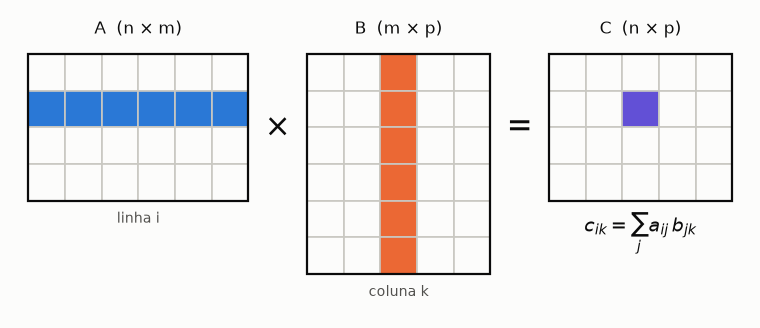

In [4]:
# Figura: definição do problema (linha i de A combinada com a coluna k de B gera c_ik)
n, m, p = 4, 6, 5
i, k = 1, 2

fig, ax = plt.subplots(figsize=(11, 4), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (n × m)", {(i, c): BLUE for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (m × p)", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C  (n × p)", {(i, k): VIOLET})
ax.text(xa + m / 2, top - n - 0.3, "linha i", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xb + p / 2, top - m - 0.3, "coluna k", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xc + p / 2, top - n - 0.3, r"$c_{ik} = \sum_j a_{ij}\,b_{jk}$", ha="center", va="top",
        fontsize=14, color=INK)
finish(ax, xc + p, top, bottom=top - m - 1.2)
save_figure(fig, "problem")

#### Versão sequencial

A versão sequencial é a **referência** para o cálculo de *speedup* e a validação de todas as outras. Os índices dos laços seguem o enunciado: $i$ percorre as linhas de $C$, $k$ percorre as colunas de $C$ e $j$ é o índice somado.

A tradução direta da fórmula é a ordem **`i-k-j`**, que calcula cada $c_{ik}$ como um produto escalar completo:

```c
for i: for k: for j: C[i][k] += A[i][j] * B[j][k];
```

Nessa ordem, o laço interno percorre `B[j][k]` **por coluna**, com saltos de $p$ elementos na memória, o que gera uma falta de cache a cada acesso. Por isso usamos a ordem **`i-j-k`**:

```c
for i: for j: { a = A[i][j]; for k: C[i][k] += a * B[j][k]; }
```

O resultado é o mesmo, porque a soma em $j$ só muda de posição no aninhamento. Agora o laço interno percorre a linha `B[j][·]` e a linha `C[i][·]` **sequencialmente** (*stride* 1). Isso aproveita as linhas de cache inteiras e permite que o compilador vetorize o laço com instruções SIMD. O número de operações é o mesmo, mas o tempo é muito menor. Usar como referência uma versão sequencial já otimizada evita *speedups* inflados nas versões paralelas.

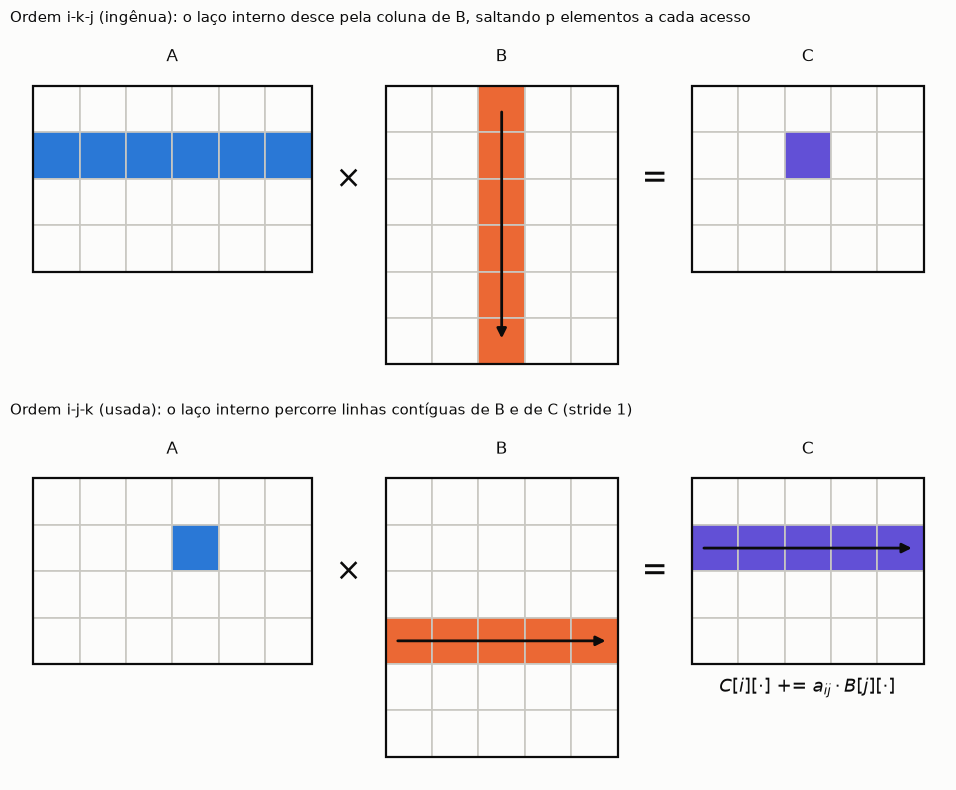

In [5]:
# Figura: padrão de acesso à memória das duas ordens de laço
n, m, p = 4, 6, 5
i, j, k = 1, 3, 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8), facecolor=SURF)

ax = axes[0]  # i-k-j: produto escalar, desce pela coluna de B
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, c): BLUE for c in range(m)})
cb = draw_matrix(ax, xb, top, m, p, "B", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C", {(i, k): VIOLET})
arrow(ax, cb(0, k), cb(m - 1, k))
ax.set_title("Ordem i-k-j (ingênua): o laço interno desce pela coluna de B, saltando p elementos a cada acesso",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

ax = axes[1]  # i-j-k: a_ij fixo, percorre linhas de B e C
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, j): BLUE})
cb = draw_matrix(ax, xb, top, m, p, "B", {(j, c): ORANGE for c in range(p)})
cc = draw_matrix(ax, xc, top, n, p, "C", {(i, c): VIOLET for c in range(p)})
h_arrow(ax, cb, j, 0, p - 1)
h_arrow(ax, cc, i, 0, p - 1)
ax.text(xc + p / 2, top - n - 0.3, r"$C[i][\cdot]$ += $a_{ij} \cdot B[j][\cdot]$", ha="center", va="top",
        fontsize=13, color=INK)
ax.set_title("Ordem i-j-k (usada): o laço interno percorre linhas contíguas de B e de C (stride 1)",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

fig.tight_layout()
save_figure(fig, "sequential_loop_order")

In [6]:
%%writefile src/sequential.c
#include "common.h"

/* C (n x p) = A (n x m) * B (m x p), c_ik = sum_j a_ij * b_jk.
 * Ordem i-j-k: o laço interno (k) percorre B e C com stride 1. */
static void matmul_seq(dims_t d, const double *A, const double *B, double *C) {
    const int n = d.n, m = d.m, p = d.p;
    for (int i = 0; i < n; i++)
        for (int j = 0; j < m; j++) {
            const double a_ij = A[(size_t)i * m + j];
            for (int k = 0; k < p; k++)
                C[(size_t)i * p + k] += a_ij * B[(size_t)j * p + k];
        }
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 1);
    init_matrices(d, A, B);

    double t0 = wall_time();
    matmul_seq(d, A, B, C);
    double t1 = wall_time();

    report("sequential", d, 1, t1 - t0, checksum(d, C));
    free(A); free(B); free(C);
    return 0;
}

Overwriting src/sequential.c


Na validação, o *checksum* calculado pela versão em C é comparado com o do produto feito pelo NumPy sobre as mesmas matrizes de entrada. Testamos uma matriz quadrada, matrizes retangulares e dois casos extremos: vetor linha por vetor coluna ($1 \times m \cdot m \times 1$) e vetor coluna por vetor linha ($n \times 1 \cdot 1 \times p$).

In [7]:
compile_c("sequential.c", "sequential")

def reference_checksum(n, m, p):
    """Mesmas matrizes de common.h, multiplicadas pelo NumPy."""
    i, j = np.indices((n, m))
    A = ((i * 7 + j * 3) % 11) / 10.0
    j, k = np.indices((m, p))
    B = ((j * 5 + k * 2) % 13) / 10.0
    return (A @ B).sum()

VALIDATION_CASES = [(256, 256, 256), (300, 200, 400), (513, 127, 64), (1, 1000, 1), (500, 1, 300)]

rows = []
for n, m, p in VALIDATION_CASES:
    res = run_once(f"./src/bin/sequential {n} {m} {p}")
    ref = reference_checksum(n, m, p)
    rows.append(dict(A=f"{n}×{m}", B=f"{m}×{p}", C=f"{n}×{p}", checksum_C=res["checksum"],
                     checksum_numpy=ref, correto=bool(np.isclose(res["checksum"], ref, rtol=1e-9))))
validation = pd.DataFrame(rows)
assert validation["correto"].all(), "A versão sequencial divergiu do NumPy!"
validation

OK: gcc -O3 src/sequential.c -o src/bin/sequential 


,A,B,C,checksum_C,checksum_numpy,correto
0,256×256,256×256,256×256,5033027.45,5033027.45,True
1,300×200,200×400,300×400,7199976.59,7199976.59,True
2,513×127,127×64,513×64,1250836.31,1250836.31,True
3,1×1000,1000×1,1×1,299.66,299.66,True
4,500×1,1×300,500×300,44867.94,44867.94,True


Para medir o tempo de execução, usamos matrizes quadradas ($n = m = p$) e executamos cada tamanho 3 vezes. Esses tempos sequenciais servem de base para o cálculo do *speedup* na Análise de desempenho.

In [8]:
SIZES = [512, 1024, 2048, 4096]

for n in SIZES:
    benchmark(f"./src/bin/sequential {n} {n} {n}", reps=3)

results_table()

sequential   (512×512)·(512×512)      workers=  1 | tempo médio =   0.0302 s (± 0.0013) | checksum = 4.0264929080e+07


sequential   (1024×1024)·(1024×1024)  workers=  1 | tempo médio =   0.2076 s (± 0.0046) | checksum = 3.2212234186e+08


sequential   (2048×2048)·(2048×2048)  workers=  1 | tempo médio =   3.0028 s (± 0.0089) | checksum = 2.5769810933e+09


sequential   (4096×4096)·(4096×4096)  workers=  1 | tempo médio =  26.4645 s (± 0.0828) | checksum = 2.0615843267e+10


,impl,n,m,p,workers,mean_s,std_s,min_s,checksum
0,sequential,512,512,512,1,0.030167,0.001319,0.028645,4.026493e+07
1,sequential,1024,1024,1024,1,0.207641,0.004594,0.204861,3.221223e+08
2,sequential,2048,2048,2048,1,3.002806,0.008941,2.993743,2.576981e+09
3,sequential,4096,4096,4096,1,26.464484,0.082757,26.374983,2.061584e+10


### Modelagem e estratégia de decomposição

A multiplicação de matrizes é um problema de **paralelismo de dados**: a mesma operação é aplicada a um grande volume de dados, sem dependências entre os resultados. Nesta seção, analisamos onde está o custo do programa, como dividir o trabalho entre os *workers* (threads, processos ou threads da GPU) e quais são os impactos dessa divisão no balanceamento de carga, no uso do cache, na comunicação e na granularidade. As decisões tomadas aqui orientam as três implementações paralelas.

#### Hotspot

O programa tem três etapas: inicializar $A$ e $B$, multiplicar e calcular o *checksum*. A inicialização toca $nm + mp$ elementos e o *checksum* toca $np$, ou seja, as duas são $O(n^2)$ para matrizes quadradas. A multiplicação executa $2nmp$ operações, que é $O(n^3)$. Com $n = 4096$, isso significa cerca de 50 milhões de acessos na inicialização e no *checksum* contra 137 bilhões de operações de ponto flutuante na multiplicação.

O *hotspot* é, portanto, o laço triplo da multiplicação, e é só ele que vale a pena paralelizar. A célula abaixo confirma isso medindo o tempo total do processo e comparando com o tempo da multiplicação reportado pelo próprio programa.

In [9]:
import time

rows = []
for n in [1024, 2048]:
    t0 = time.perf_counter()
    res = run_once(f"./src/bin/sequential {n}")
    total = time.perf_counter() - t0
    rows.append(dict(n=n, tempo_total_s=total, tempo_multiplicacao_s=res["time_s"],
                     fracao_multiplicacao=f"{100 * res['time_s'] / total:.1f}%"))
pd.DataFrame(rows)

,n,tempo_total_s,tempo_multiplicacao_s,fracao_multiplicacao
0,1024,0.219320,0.203448,92.8%
1,2048,3.137014,3.099895,98.8%


O tempo restante inclui a criação do processo, a alocação, a inicialização e o *checksum*, e diminui proporcionalmente à medida que $n$ cresce. Pela Lei de Amdahl, a fração sequencial que sobra limita muito pouco o *speedup* possível, e por isso as versões paralelas mantêm a inicialização sequencial e paralelizam apenas a multiplicação.

#### Decomposição de dados

A fórmula $c_{ik} = \sum_j a_{ij}\,b_{jk}$ tem três índices, e cada um poderia ser dividido entre os *workers*. Os índices $i$ e $k$ identificam elementos diferentes de $C$, que são independentes entre si. Já o índice $j$ é o da soma: dividir $j$ faria vários *workers* acumularem no mesmo $c_{ik}$, o que exige operações atômicas ou uma etapa extra de redução, além de mais comunicação. Por isso adotamos uma **decomposição do resultado** (*output decomposition*): cada *worker* fica responsável por um conjunto de elementos de $C$ e calcula a soma em $j$ inteira, sem precisar se coordenar com os demais.

A figura abaixo mostra três formas de dividir $C$, da mais fina para a mais grossa:

- **por elemento**: cada tarefa calcula um único $c_{ik}$, gerando $n \cdot p$ tarefas de $2m$ operações cada. É granularidade fina demais para threads de CPU, mas é o modelo natural da GPU, que executa milhares de threads leves agrupadas em blocos;
- **por faixas de linhas (1D)**: cada *worker* recebe um bloco de linhas consecutivas de $C$. Para isso, ele precisa da faixa correspondente de $A$ e da matriz $B$ inteira;
- **por blocos 2D**: os *workers* formam uma grade e cada um calcula um bloco de $C$. Cada *worker* precisa de uma faixa de linhas de $A$ e de uma faixa de colunas de $B$, e não mais de $B$ inteira.

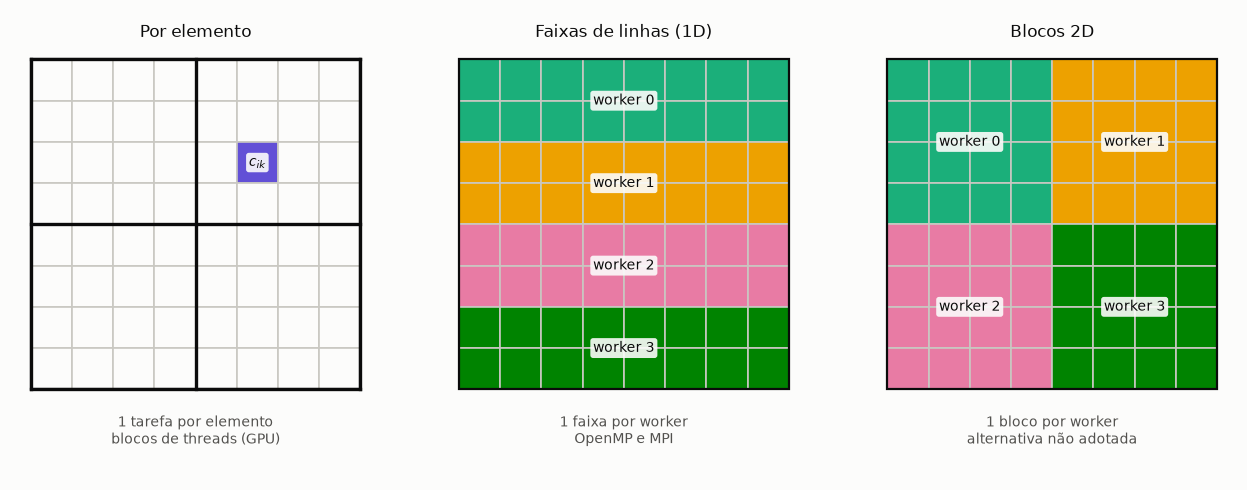

In [10]:
# Figura: três formas de decompor C entre os workers
N = 8
fig, axes = plt.subplots(1, 3, figsize=(13, 5), facecolor=SURF)

ax = axes[0]  # por elemento, agrupados em blocos de threads (GPU)
cc = draw_matrix(ax, 0, N, N, N, "Por elemento", {(2, 5): VIOLET})
for t in range(0, N + 1, 4):  # fronteiras dos blocos de threads
    ax.plot([t, t], [0, N], color=INK, lw=2.4); ax.plot([0, N], [t, t], color=INK, lw=2.4)
label(ax, cc(2, 5), r"$c_{ik}$", 10)
ax.text(N / 2, -0.6, "1 tarefa por elemento\nblocos de threads (GPU)", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[1]  # faixas de linhas 1D
fills = {(r, c): WORKER_COLORS[r // 2] for r in range(N) for c in range(N)}
cc = draw_matrix(ax, 0, N, N, N, "Faixas de linhas (1D)", fills)
for w in range(4):
    label(ax, (N / 2, N - 2 * w - 1), f"worker {w}")
ax.text(N / 2, -0.6, "1 faixa por worker\nOpenMP e MPI", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[2]  # blocos 2D
fills = {(r, c): WORKER_COLORS[2 * (r // 4) + c // 4] for r in range(N) for c in range(N)}
draw_matrix(ax, 0, N, N, N, "Blocos 2D", fills)
for w in range(4):
    label(ax, (2 + 4 * (w % 2), N - 2 - 4 * (w // 2)), f"worker {w}")
ax.text(N / 2, -0.6, "1 bloco por worker\nalternativa não adotada", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

fig.tight_layout()
save_figure(fig, "decomposition_options")

Para as versões em CPU (OpenMP e MPI), adotamos a **decomposição 1D por faixas de linhas de $C$**. Ela tem três vantagens. Primeiro, cada faixa de $C$ e de $A$ é um trecho contíguo da memória, porque as matrizes estão em ordem por linhas, então uma faixa pode ser enviada em uma única mensagem MPI e cada thread escreve em uma região própria de $C$. Segundo, ela preserva o laço `i-j-k` da versão sequencial sem nenhuma alteração: cada *worker* apenas executa o laço $i$ sobre as suas linhas, o que permite comparar as versões de forma justa. Terceiro, a quantidade de faixas (uma por *worker*) é pequena e fácil de distribuir.

A decomposição 2D reduz a comunicação quando há muitos processos, como discutido mais adiante, mas exige algoritmos mais elaborados (como SUMMA ou Cannon) e, com os poucos processos disponíveis em uma única máquina, o ganho é pequeno. Para a GPU, adotamos a **decomposição por elemento**, com uma thread por $c_{ik}$ e threads agrupadas em blocos 2D que cobrem *tiles* de $C$.

#### Balanceamento de carga

Todo elemento $c_{ik}$ custa exatamente $m$ multiplicações e $m$ somas, independentemente de sua posição ou dos valores das matrizes. A carga é, portanto, **uniforme e conhecida antes da execução**, e uma distribuição estática já deveria ser balanceada. Mesmo assim, há três situações em que surge desbalanceamento.

A primeira é a **divisão não exata**. Quando $n$ não é múltiplo do número de *workers* $P$, alguns recebem $\lceil n/P \rceil$ linhas e outros $\lfloor n/P \rfloor$. A figura abaixo mostra $n = 10$ linhas divididas entre $P = 4$ *workers*: os dois primeiros recebem 3 linhas e os dois últimos, 2. Como o tempo total é o do *worker* mais lento, os que recebem menos linhas ficam ociosos no final. A diferença é de no máximo uma linha, o que é desprezível para $n$ grande: com $n = 4096$ e $P = 12$, os *workers* recebem 342 ou 341 linhas, um desbalanceamento de 0,3%. Distribuímos o resto entre os primeiros *workers* (uma linha extra para cada), em vez de colocar todo o resto no último, para manter essa diferença em no máximo uma linha.

A segunda é a **heterogeneidade do hardware**. A máquina de testes do grupo tem um processador Intel Core i5-13450HX com 6 núcleos de desempenho (P-cores, até 4,6 GHz, com *hyper-threading*) e 4 núcleos de eficiência (E-cores, até 3,4 GHz), totalizando 16 threads. Com uma divisão estática em partes iguais, as threads que caem nos E-cores ou que dividem um P-core com outra thread terminam depois das demais, e todas esperam por elas. Mesmo com carga uniforme, a capacidade dos *workers* não é uniforme. No OpenMP, comparamos o escalonamento `static` com o `dynamic`, em que as threads pegam novos blocos de linhas à medida que terminam os anteriores, para medir esse efeito. No MPI, a divisão é feita uma única vez no início e não pode ser reajustada, então o processo mais lento define o tempo.

A terceira são as **matrizes muito retangulares**. Se $n < P$ (por exemplo, $A$ com 2 linhas e 16 threads), a decomposição por linhas deixa *workers* sem trabalho. Esse caso aparece apenas na validação e não nos testes de desempenho, que usam matrizes quadradas. Ele poderia ser tratado dividindo as colunas de $C$ quando $p$ é maior que $n$.

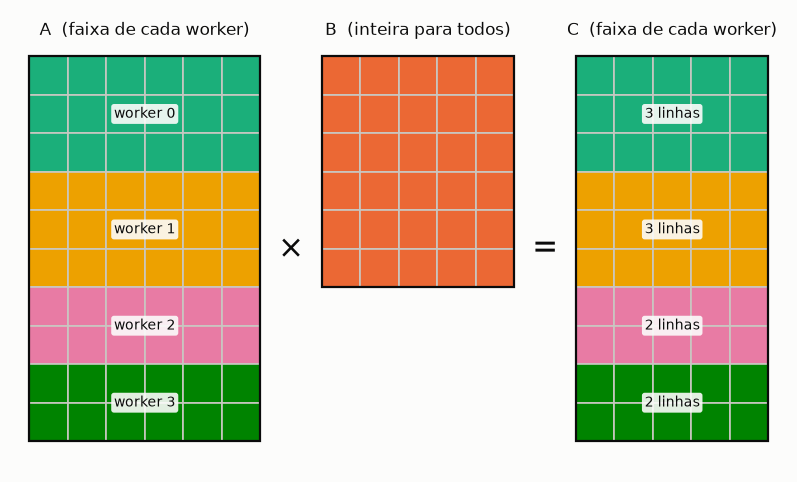

Divisão para n = 4096:
  P =  4: 1024 a 1024 linhas por worker (desbalanceamento de 0.00%)
  P = 12: 342 a 341 linhas por worker (desbalanceamento de 0.29%)
  P = 16: 256 a 256 linhas por worker (desbalanceamento de 0.00%)


In [11]:
def row_ranges(n, workers):
    """Divide n linhas entre workers: os primeiros n % workers recebem uma linha a mais."""
    base, extra = divmod(n, workers)
    ranges, start = [], 0
    for w in range(workers):
        size = base + (1 if w < extra else 0)
        ranges.append((start, start + size))
        start += size
    return ranges

# Figura: decomposição 1D por linhas com divisão não exata (n = 10, P = 4)
n, m, p, workers = 10, 6, 5, 4
ranges = row_ranges(n, workers)
owner = {r: w for w, (a, b) in enumerate(ranges) for r in range(a, b)}

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (inteira para todos)", {(r, c): ORANGE for r in range(m) for c in range(p)})
draw_matrix(ax, xc, top, n, p, "C  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(p)})
for w, (a, b) in enumerate(ranges):
    mid = top - (a + b) / 2
    label(ax, (xa + m / 2, mid), f"worker {w}")
    label(ax, (xc + p / 2, mid), f"{b - a} linhas")
finish(ax, xc + p, top, bottom=-0.8)
save_figure(fig, "row_decomposition")

print("Divisão para n = 4096:")
for P_ in [4, 12, 16]:
    sizes = [b - a for a, b in row_ranges(4096, P_)]
    print(f"  P = {P_:>2}: {max(sizes)} a {min(sizes)} linhas por worker "
          f"(desbalanceamento de {100 * (max(sizes) - min(sizes)) / max(sizes):.2f}%)")

#### Localidade e uso do cache

Como discutido na versão sequencial, o laço `i-j-k` percorre as linhas de $B$ e de $C$ de forma contígua, o que garante **localidade espacial**: cada linha de cache de 64 bytes trazida da memória contém 8 valores `double` que serão usados em seguida. A **localidade temporal**, ou seja, o reaproveitamento de dados que já estão no cache, depende do tamanho das matrizes:

- a linha $C[i]$ ($8p$ bytes) é reaproveitada para todos os $j$ e cabe no cache L1/L2;
- a matriz $B$ inteira é percorrida uma vez para cada linha $i$. Se $B$ cabe no cache L3, ela é lida da memória principal só na primeira linha. Se não cabe, é relida da memória principal $n$ vezes.

A máquina de testes tem 20 MiB de cache L3. A matriz $B$ ocupa 8 MiB com $n = 1024$ e cabe no L3, mas ocupa 32 MiB com $n = 2048$ e 128 MiB com $n = 4096$, que não cabem. A tabela abaixo mostra o efeito disso nos tempos sequenciais medidos: o desempenho em GFLOP/s cai quase pela metade quando $B$ deixa de caber no L3, porque o laço passa a esperar pela memória principal.

In [12]:
L3_MIB = 20
seq = results_table().query("impl == 'sequential' and n == m == p").copy()
seq["B_MiB"] = seq["m"] * seq["p"] * 8 / 2**20
seq["B_cabe_no_L3"] = seq["B_MiB"] <= L3_MIB
seq["GFLOP_s"] = 2 * seq["n"] * seq["m"] * seq["p"] / seq["mean_s"] / 1e9
seq[["n", "mean_s", "B_MiB", "B_cabe_no_L3", "GFLOP_s"]].round(2)

,n,mean_s,B_MiB,B_cabe_no_L3,GFLOP_s
0,512,0.03,2.0,True,8.90
1,1024,0.21,8.0,True,10.34
2,2048,3.00,32.0,False,5.72
3,4096,26.46,128.0,False,5.19


Isso tem duas consequências para as versões paralelas. Nas versões em CPU, todas as threads de um mesmo processador dividem o cache L3 e a banda de memória. Com a decomposição por linhas, todas leem a matriz $B$ inteira, então para matrizes grandes elas competem pela mesma banda de memória, e o *speedup* tende a crescer menos do que o número de threads. Esse efeito será observado na Análise de desempenho. Uma vantagem da decomposição por linhas é que, como cada thread escreve em uma faixa própria de $C$, não há **falso compartilhamento** (*false sharing*): duas threads só podem escrever na mesma linha de cache na fronteira entre faixas, o que é desprezível.

Técnicas de *blocking* (*tiling*) dividem $B$ em blocos que cabem no cache e os reaproveitam para várias linhas de $A$ antes de descartá-los. Nas versões em CPU, decidimos **não** usar *tiling* e manter o mesmo laço da versão sequencial, para que o *speedup* meça apenas o ganho do paralelismo, e não o de uma otimização de cache. Na GPU, ao contrário, o *tiling* com memória compartilhada é essencial: cada bloco de threads carrega *tiles* de $A$ e $B$ na memória compartilhada do chip, muito mais rápida que a memória global, e todas as threads do bloco os reaproveitam.

#### Comunicação

Em **memória compartilhada (OpenMP)**, não há troca explícita de mensagens: todas as threads leem $A$ e $B$ diretamente da memória comum. Como $A$ e $B$ só são lidas e cada thread escreve em linhas diferentes de $C$, não há condições de corrida e nenhuma sincronização é necessária além da barreira implícita no fim do laço paralelo. A "comunicação" se resume ao tráfego entre a memória e os caches, discutido acima.

Em **memória distribuída (MPI)**, cada processo tem sua própria memória, e os dados precisam ser enviados explicitamente. Partindo do processo 0, que tem $A$ e $B$, a decomposição por linhas usa três operações coletivas:

1. `MPI_Scatterv` envia a cada processo a sua faixa de linhas de $A$ (a versão `v` permite faixas de tamanhos diferentes, como no caso de divisão não exata);
2. `MPI_Bcast` envia a matriz $B$ inteira para todos os processos;
3. `MPI_Gatherv` reúne no processo 0 as faixas de $C$ calculadas.

O custo dominante é o *broadcast* de $B$, que cresce com o número de processos: são $(P-1) \cdot mp$ valores enviados. Na decomposição 2D, cada processo receberia apenas uma faixa de $A$ e uma de $B$, e o volume total cairia para cerca de $\sqrt{P}\,(nm + mp)$. A tabela abaixo compara os volumes para $n = 4096$ e mostra a razão entre computação e comunicação de cada processo na decomposição 1D.

In [13]:
def comm_volume_mib(n, m, p, P):
    """Volume total enviado (MiB) pelas decomposições 1D por linhas e 2D em blocos.
    A 2D supõe uma grade sqrt(P) x sqrt(P), por isso P deve ser um quadrado perfeito."""
    to_mib = 8 / 2**20
    one_d = ((P - 1) / P * n * m + (P - 1) * m * p + (P - 1) / P * n * p) * to_mib
    two_d = (P ** 0.5 * (n * m + m * p) + n * p) * to_mib
    return one_d, two_d

n = m = p = 4096
rows = []
for P_ in [4, 9, 16, 25]:
    v1, v2 = comm_volume_mib(n, m, p, P_)
    flops_per_proc = 2 * n * m * p / P_
    values_per_proc = (n / P_) * m + m * p + (n / P_) * p   # faixa de A + B inteira + faixa de C
    rows.append(dict(P=P_, volume_1D_MiB=round(v1), volume_2D_MiB=round(v2),
                     flops_por_valor_1D=round(flops_per_proc / values_per_proc)))
pd.DataFrame(rows)

,P,volume_1D_MiB,volume_2D_MiB,flops_por_valor_1D
0,4,576,640,1365
1,9,1252,896,745
2,16,2160,1152,455
3,25,3318,1408,303


Com poucos processos, a diferença entre 1D e 2D é pequena, e com $P = 4$ a decomposição 1D chega a enviar menos dados. A vantagem da 2D só se torna relevante com dezenas de processos, típicos de um *cluster*. Como todos os processos rodam na mesma máquina, as mensagens MPI passam pela memória compartilhada, sem rede, e a implementação mais simples é suficiente. Por isso mantemos a decomposição 1D, cientes de que ela não escalaria bem para muitos nós.

A razão entre computação e comunicação diminui à medida que $P$ aumenta: cada processo faz menos operações, mas continua recebendo $B$ inteira. Ainda assim, para $n = 4096$, cada valor recebido é usado em centenas de operações, o que indica que a comunicação não deve dominar o tempo. Para matrizes pequenas, ao contrário, o custo fixo das mensagens pode superar o ganho do paralelismo.

Na **GPU**, a comunicação é a cópia de dados entre a memória do computador (*host*) e a memória da placa (*device*) pelo barramento PCIe: $A$ e $B$ são copiadas para a GPU e $C$ é copiada de volta, uma única vez. São $nm + mp + np$ valores, ou 384 MiB para $n = 4096$, um volume fixo que não depende de quantas threads são usadas.

Para que a comparação com a versão sequencial seja justa, o tempo medido em todas as versões inclui toda a comunicação necessária para obter $C$ a partir de $A$ e $B$: as operações coletivas no MPI e as cópias entre *host* e *device* na GPU. Sempre que possível, também mediremos separadamente o tempo de comunicação, para analisar seu peso no total.

#### Granularidade

A granularidade é a quantidade de trabalho de cada tarefa em relação ao custo de criá-la, distribuí-la e sincronizá-la. Tarefas muito finas geram muito custo de gerenciamento, e tarefas muito grossas podem deixar *workers* ociosos se a carga não for bem dividida. Cada plataforma tem um ponto de equilíbrio diferente.

No OpenMP, a menor unidade que distribuímos é uma linha de $C$, com $2mp$ operações (33 milhões para $n = 4096$), muito acima do custo de escalonar uma tarefa, que é da ordem de microssegundos. Com o escalonamento `static`, cada thread recebe um único bloco de $n/P$ linhas, que é a granularidade mais grossa possível e tem custo de gerenciamento praticamente zero. Com o `dynamic`, as threads pegam blocos menores (*chunks*) conforme terminam, o que tem um custo maior, mas compensa a diferença de velocidade entre os núcleos. O tamanho do *chunk* é um parâmetro a ser ajustado experimentalmente.

No MPI, a granularidade é a mais grossa: uma única faixa por processo, porque cada envio de mensagem tem um custo fixo de latência e enviar muitas faixas pequenas seria ineficiente.

Na GPU, a granularidade é a mais fina: uma thread por elemento de $C$, ou seja, cerca de 16,8 milhões de threads para $n = 4096$. Isso só é viável porque as threads da GPU são extremamente leves e são escalonadas pelo hardware, e porque é preciso ter muito mais threads do que núcleos para esconder a latência da memória global. As threads são agrupadas em blocos (por exemplo, $16 \times 16 = 256$ threads), e o tamanho do bloco define tanto o reaproveitamento de dados no *tiling* quanto a ocupação dos multiprocessadores da GPU.

#### Resumo das decisões

| | OpenMP | MPI | GPU (CUDA) |
|---|---|---|---|
| Decomposição | faixas de linhas de $C$ | faixas de linhas de $C$ | um elemento de $C$ por thread, *tiles* 2D por bloco |
| Granularidade | um bloco por thread (`static`) ou *chunks* (`dynamic`) | uma faixa por processo | uma thread por elemento |
| Comunicação | nenhuma explícita, $B$ compartilhada | `Scatterv` de $A$, `Bcast` de $B$, `Gatherv` de $C$ | cópias *host* ↔ *device* |
| Balanceamento | divisão estática com resto distribuído; `dynamic` para núcleos heterogêneos | divisão estática com resto distribuído | blocos de borda parcialmente ociosos |
| Localidade | laço `i-j-k`, sem *tiling* | laço `i-j-k`, sem *tiling* | *tiling* com memória compartilhada |

### Implementação com memória compartilhada (OpenMP)

### Implementação com memória distribuída (MPI)

### Implementação em GPU

### Análise de desempenho